In [121]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [122]:
df = pd.read_csv('../../course_assignments/homework9/solar_system.csv')

In [123]:
df.shape

(20, 11)

In [124]:
# There are 20 rows and 11 columns

In [125]:
df.head()

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
0,Mass (10^24kg),0.330,4.87,5.97,0.073,0.642,1898,568,86.8,102,0.0130
1,Diameter (km),4879,12104,12756,3475,6792,142984,120536,51118,49528,2376
2,Density (kg/m^3),5429,5243,5514,3340,3934,1326,687,1270,1638,1850
3,Gravity (m/s^2),3.7,8.9,9.8,1.6,3.7,23.1,9.0,8.7,11.0,0.7
4,Escape Velocity (km/s),4.3,10.4,11.2,2.4,5.0,59.5,35.5,21.3,23.5,1.3


In [126]:
df.tail()

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
15,Mean Temperature (C),167,464,15,-20,-65,-110,-140,-195,-200,-225
16,Surface Pressure (bars),0,92,1,0,0.01,Unknown,Unknown,Unknown,Unknown,0.00001
17,Number of Moons,0,0,1,0,2,95,274,28,16,5
18,Ring System?,No,No,No,No,No,Yes,Yes,Yes,Yes,No
19,Global Magnetic Field?,Yes,No,Yes,No,No,Yes,Yes,Yes,Yes,Unknown


In [127]:
df.columns.tolist()

['Attribute',
 'Mercury',
 'Venus',
 'Earth',
 'Moon',
 'Mars',
 'Jupiter',
 'Saturn',
 'Uranus',
 'Neptune',
 'Pluto']

In [128]:
df["Attribute"]

0                  Mass (10^24kg)
1                   Diameter (km)
2                Density (kg/m^3)
3                 Gravity (m/s^2)
4          Escape Velocity (km/s)
5         Rotation Period (hours)
6           Length of Day (hours)
7     Distance from Sun (10^6 km)
8            Perihelion (10^6 km)
9              Aphelion (10^6 km)
10          Orbital Period (days)
11        Orbital Velocity (km/s)
12      Orbital Inclination (deg)
13           Orbital Eccentricity
14       Obliquity to Orbit (deg)
15           Mean Temperature (C)
16        Surface Pressure (bars)
17                Number of Moons
18                   Ring System?
19         Global Magnetic Field?
Name: Attribute, dtype: str

In [129]:
orbital_periods = df.iloc[10, 1:].astype(float)
orbital_periods

Mercury       88.0
Venus        224.7
Earth        365.2
Moon          27.3
Mars         687.0
Jupiter     4331.0
Saturn     10747.0
Uranus     30589.0
Neptune    59800.0
Pluto      90560.0
Name: 10, dtype: float64

In [130]:
perihelion = df.iloc[8, 1:].astype(float)
perihelion

Mercury      46.000
Venus       107.500
Earth       147.100
Moon          0.363
Mars        206.700
Jupiter     740.600
Saturn     1357.600
Uranus     2732.700
Neptune    4471.100
Pluto      4436.800
Name: 8, dtype: float64

In [131]:
aphelion = df.iloc[9, 1:].astype(float)
aphelion

Mercury      69.800
Venus       108.900
Earth       152.100
Moon          0.406
Mars        249.300
Jupiter     816.400
Saturn     1506.500
Uranus     3001.400
Neptune    4558.900
Pluto      7375.900
Name: 9, dtype: float64

In [132]:
# Perihelion is the point where the planet/object is closest to the sun (min distance)
# Aphelion is the point where the planet/object is furthest from the sun (max distance) 
# Semi-major axis is the half of the distance of the longest diameter of the orbit

In [133]:
semi_major_axis = (perihelion + aphelion) / 2
semi_major_axis

Mercury      57.9000
Venus       108.2000
Earth       149.6000
Moon          0.3845
Mars        228.0000
Jupiter     778.5000
Saturn     1432.0500
Uranus     2867.0500
Neptune    4515.0000
Pluto      5906.3500
dtype: float64

In [134]:
semi_majors = pd.Series(semi_major_axis, name = "Semi-major axis (10^6 km)")
df = pd.concat([df, semi_majors.to_frame().T])
df

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
0,Mass (10^24kg),0.330,4.87,5.97,0.073,0.642,1898,568,86.8,102,0.0130
1,Diameter (km),4879,12104,12756,3475,6792,142984,120536,51118,49528,2376
2,Density (kg/m^3),5429,5243,5514,3340,3934,1326,687,1270,1638,1850
3,Gravity (m/s^2),3.7,8.9,9.8,1.6,3.7,23.1,9.0,8.7,11.0,0.7
4,Escape Velocity (km/s),4.3,10.4,11.2,2.4,5.0,59.5,35.5,21.3,23.5,1.3
5,Rotation Period (hours),1407.6,-5832.5,23.9,655.7,24.6,9.9,10.7,-17.2,16.1,-153.3
6,Length of Day (hours),4222.6,2802.0,24.0,708.7,24.7,9.9,10.7,17.2,16.1,153.3
7,Distance from Sun (10^6 km),57.9,108.2,149.6,0.384,228.0,778.5,1432.0,2867.0,4515.0,5906.4
8,Perihelion (10^6 km),46.0,107.5,147.1,0.363,206.7,740.6,1357.6,2732.7,4471.1,4436.8
9,Aphelion (10^6 km),69.8,108.9,152.1,0.406,249.3,816.4,1506.5,3001.4,4558.9,7375.9


In [135]:
df.shape

(21, 11)

In [136]:
# There are 21 rows and 11 columns

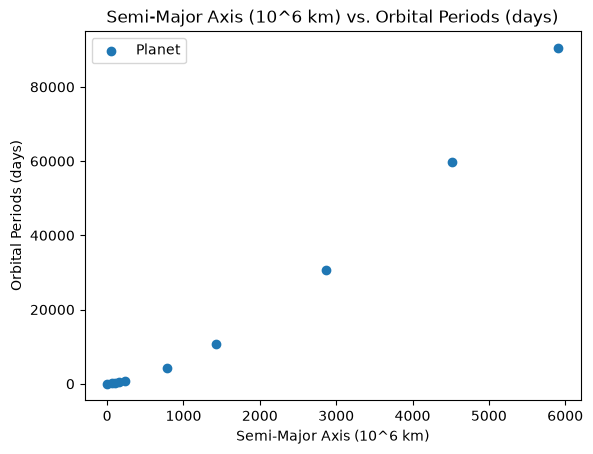

In [137]:
plt.scatter(semi_major_axis, orbital_periods, label = "Planet")
plt.xlabel("Semi-Major Axis (10^6 km)")
plt.ylabel("Orbital Periods (days)")
plt.title("Semi-Major Axis (10^6 km) vs. Orbital Periods (days)")
plt.legend()
plt.show()

In [138]:
def keplers_third_law(a, m):
    return m * a ** 1.5

In [139]:
popt, pcov = curve_fit(keplers_third_law, semi_major_axis, orbital_periods)

In [140]:
best_fit_parameter = popt[0]
best_fit_parameter

np.float64(0.1987998191813986)

In [141]:
f"Fitted model: T = {best_fit_parameter:.2f} * a ** 1.5"

'Fitted model: T = 0.20 * a ** 1.5'

In [142]:
residuals = orbital_periods - keplers_third_law(semi_major_axis, best_fit_parameter)
chi2 = np.sum(residuals**2)
dof = len(semi_major_axis) - len(popt)
chi2_reduced = chi2 / dof
chi2_reduced

np.float64(41276.70608939304)

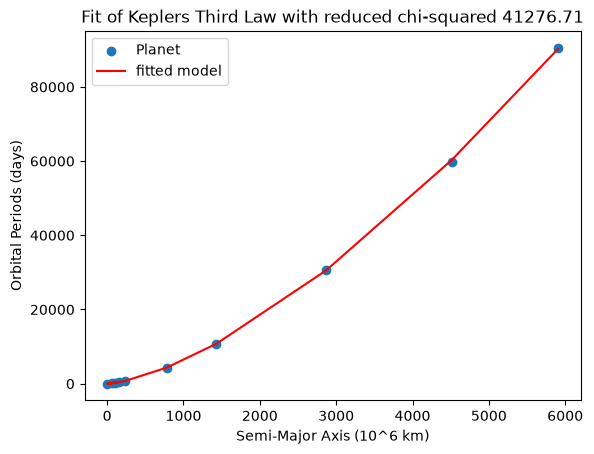

In [143]:
plt.scatter(semi_major_axis, orbital_periods, label = "Planet")
plt.plot(semi_major_axis, keplers_third_law(semi_major_axis, best_fit_parameter), color = "red", label = "fitted model")
plt.xlabel("Semi-Major Axis (10^6 km)")
plt.ylabel("Orbital Periods (days)")
plt.title(f"Fit of Keplers Third Law with reduced chi-squared {chi2_reduced:.2f}")
plt.legend()
plt.show()

In [144]:
df.to_csv("kepler.csv", index=False)